# Module 2 — Query your MyGPT library through the API

**Time:** 20 min · **Needs:** module 1 library, `.env` filled in

You will:
1. Connect and list libraries
2. Run the RAG steps one at a time: **retrieve → generate → score**
3. Run a batch of questions and save the results for module 3

In [3]:
import sys
from pathlib import Path

# Make the repo root importable whether Jupyter was started from the root or this folder
ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from common.mygpt_client import MyGPTClient, outputs_dir, load_fallback_pubmedqa  # noqa: E402
OUT = outputs_dir()

## 1. Connect

In [4]:
client = MyGPTClient.from_env()       # signs in with MYGPT_USERNAME / MYGPT_PASSWORD
print("Backend:", client.base_url, "| signed in:", bool(client.access_token))
print("Library:", client.dataset, "| LLM:", client.llm, "| embeddings:", client.embedding_model)

import pandas as pd
pd.DataFrame(client.list_datasets())

Backend: http://host.docker.internal:8000 | signed in: True
Library: workshop-library-A | LLM: llama3:latest | embeddings: nomic-embed-text:latest


""


In [5]:
payload = {
    "dataset": client.dataset,
    "user_email": "",
    "user_group": "",
}
docs = client._post("/api/get_documents/", payload)
print(docs.get("dataset_type"), "-", len(docs.get("documents", [])), "documents")
pd.DataFrame(docs.get("documents", [])).head(10)

papers - 397 documents


,paper_title,paper_attachment,highlighted_attachment,paper_dataset,paper_date_time
0,BioASQ_Batch_001,papers/workshop-library-A/paper1.pdf,papers/workshop-library-A/paper1_highlighted_3...,1,2026-11-15T01:32:26.737Z
1,BioASQ_Batch_002,papers/workshop-library-A/paper2.pdf,papers/workshop-library-A/paper2_highlighted_a...,1,2026-11-15T01:32:27.069Z
2,BioASQ_Batch_003,papers/workshop-library-A/paper3.pdf,papers/workshop-library-A/paper3_highlighted_8...,1,2026-11-15T01:32:27.401Z
3,BioASQ_Batch_004,papers/workshop-library-A/paper4.pdf,papers/workshop-library-A/paper4_highlighted_r...,1,2026-11-15T01:32:27.850Z
4,BioASQ_Batch_005,papers/workshop-library-A/paper5.pdf,papers/workshop-library-A/paper5_highlighted_D...,1,2026-11-15T01:32:28.137Z
5,BioASQ_Batch_006,papers/workshop-library-A/paper6.pdf,papers/workshop-library-A/paper6_highlighted_I...,1,2026-11-15T01:32:28.434Z
6,BioASQ_Batch_007,papers/workshop-library-A/paper7.pdf,papers/workshop-library-A/paper7_highlighted_8...,1,2026-11-15T01:32:28.740Z
7,BioASQ_Batch_008,papers/workshop-library-A/paper8.pdf,papers/workshop-library-A/paper8_highlighted_y...,1,2026-11-15T01:32:29.050Z
8,BioASQ_Batch_009,papers/workshop-library-A/paper9.pdf,-,1,2026-11-15T01:32:29.372Z
9,BioASQ_Batch_010,papers/workshop-library-A/paper10.pdf,-,1,2026-11-15T01:32:29.603Z


## 2. RAG step by step

### 2a. Retrieve — `POST /api/get_context/`
Returns the retrieved chunks (`sources`) and the **question relevance score (QRS)** with its parts:
semantic, keyword (BM25) and rerank.

In [6]:
question = "Do glioblastoma tumors have a high degree of lymphocyte infiltration?"   # ← try your own

ctx = client.get_context(question, max_chunks=5)
print({k: ctx.get(k) for k in ["relevance_score", "semantic_score", "keyword_score", "rerank_score"]})
for s in (ctx.get("sources") or [])[:5]:
    print("-", {k: v for k, v in s.items() if k != "context"})

{'relevance_score': 69.0, 'semantic_score': 75.0, 'keyword_score': 45.0, 'rerank_score': 80.0}
- {'document': 'BioASQ_Batch_001', 'page': 4, 'start': '', 'stop': '', 'vector_distance_raw': 153.48, 'vector_score': 0.755, 'rank': 1, 'reranked_score': 0.984, 'bm25_score_raw': 0, 'bm25_score': 0, 'bm25_rank': 0, 'color_code': 'green'}
- {'document': 'BioASQ_Batch_001', 'page': 4, 'bm25_score_raw': 10.03, 'bm25_score': 0.5009999871253967, 'vector_score': 0, 'rank': 2, 'reranked_score': 0.825, 'vector_distance_raw': 0, 'color_code': 'green'}
- {'document': 'BioASQ_Batch_191', 'page': 1, 'bm25_score_raw': 8.85, 'bm25_score': 0.44200000166893005, 'vector_score': 0, 'rank': 3, 'reranked_score': 0.401, 'vector_distance_raw': 0, 'color_code': 'yellow'}
- {'document': 'BioASQ_Batch_001', 'page': 1, 'bm25_score_raw': 8.22, 'bm25_score': 0.41100001335144043, 'vector_score': 0, 'rank': 1, 'reranked_score': 0.998, 'vector_distance_raw': 0, 'color_code': 'yellow'}


### 2b. Generate — `POST /api/ollama_generate/`

In [7]:
from common.mygpt_client import RAG_PROMPT

context_text = ctx.get("context") or "\n\n".join(s.get("context", "") for s in ctx.get("sources", []))
answer = client.generate(RAG_PROMPT.format(context=context_text, question=question))
print(answer)

According to the provided context, glioblastoma tumors have a low degree of lymphocyte infiltration. Specifically, it is mentioned that "low lymphocyte infiltration" is one of the characteristics of glioblastoma tumors.


### 2c. Score — `POST /api/save_answer/`
MyGPT compares the answer with the retrieved chunks, which gives the **answer relevance score (ARS)** and the
**hallucination index (HI)**.

In [8]:
scores = client.score_answer(question, answer)
{k: scores.get(k) for k in ["relevance_score", "semantic_score", "keyword_score",
                            "hallucination_index_by_equation", "hallucination_index_by_ml"]}

{'relevance_score': 94.0,
 'semantic_score': 64.25,
 'keyword_score': 6.08,
 'hallucination_index_by_equation': 0,
 'hallucination_index_by_ml': 25.0}

## 3. All in one call: `client.ask()`

In [9]:
row = client.ask("What is the boiling point of tungsten?")   # off-topic control question
{k: row[k] for k in ["answer", "QRS", "ARS", "HI", "HI_equation"]}

{'answer': 'The library does not contain the answer.',
 'QRS': 64.0,
 'ARS': 64.0,
 'HI': 73.0,
 'HI_equation': 27.0}

**Discuss:** how do QRS and HI for the off-topic question compare with the on-topic one above?

## 4. Batch query and save

In [ ]:
questions = pd.read_csv(
    ROOT
    / "data"
    / "BioASQ"
    / "questions_25.csv"
)["questions"].head(5).tolist()
# Remove .head(5) to query all 25 BioASQ questions.

rows = []
for i, q in enumerate(questions, 1):
    print(f"[{i}/{len(questions)}] {q}")
    try:
        rows.append(client.ask(q))
    except Exception as exc:
        print("   failed:", exc)
        rows.append({"question": q, "error": str(exc)})

results = pd.DataFrame(rows)
results.drop(columns=["context"], errors="ignore").to_csv(OUT / "02_query_results.csv", index=False)
results[["question", "QRS", "ARS", "HI"]]

[1/5] Do glioblastoma tumors have a high degree of lymphocyte infiltration?
[2/5] Has any single infectious agent been identified as the cause of irritable bowel syndrome?
[3/5] Is pollinosis another name for allergies to tree or grass pollen?
[4/5] Which gene shapes the 3D enhancer network of the developing T cell genome?
[5/5] Do mesenchymal-like glioblastoma cells show increased immune evasion?


,question,QRS,ARS,HI
0,Do glioblastoma tumors have a high degree of l...,69.0,93.0,24.0
1,Has any single infectious agent been identifie...,90.0,96.0,38.0
2,Is pollinosis another name for allergies to tr...,49.0,94.0,30.0
3,Which gene shapes the 3D enhancer network of t...,54.0,100.0,37.0
4,Do mesenchymal-like glioblastoma cells show in...,74.0,100.0,31.0


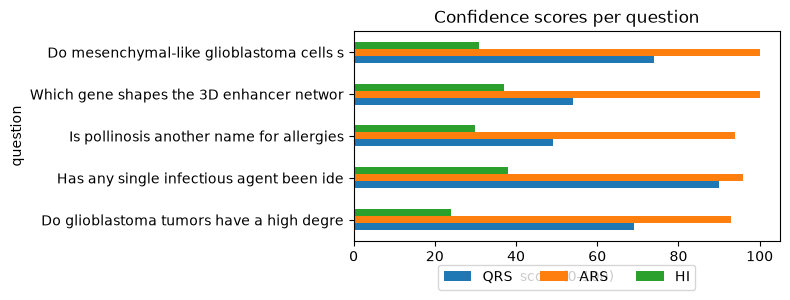

In [11]:
import matplotlib.pyplot as plt

plot = results.set_index(results["question"].str.slice(0, 40))[["QRS", "ARS", "HI"]].astype(float)
ax = plot.plot.barh(figsize=(8, 0.5 * len(plot) + 1), legend=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
plt.xlabel("score (0-100)")
plt.title("Confidence scores per question")
plt.tight_layout(rect=(0, 0.1, 1, 1))

## Exercises
1. Rerun the batch with `client.ask(q, max_chunks=10)`. Do ARS and HI change?
2. Set `client.dataset = "workshop-library-b"` (your module 1 comparison library) and compare the two CSVs.
3. Which question has a **high QRS but a poor answer**? Keep it in mind, because module 3 measures this systematically.